# What is the Goal?
The ultimate goal of Document Classification is to teach a computer to automatically read a completely new, unknown document and accurately guess what topic it is about, without a human having to read it first.

In this specific project, the goal is to teach computer to specializes in telling the difference between Space articles and Automobile articles.

# Step 1: Building the Custom Dataset

In [17]:
import requests
from bs4 import BeautifulSoup

# 1. Define the robust web scraper (with security bypass)
def fetch_clean_text(url):
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    response = requests.get(url, headers=headers)
    soup = BeautifulSoup(response.text, 'html.parser')
    paragraphs = soup.find_all('p')
    return " ".join([p.get_text() for p in paragraphs])

# 2. Define the comprehensive URL lists
space_urls = [
    "https://en.wikipedia.org/wiki/Space_exploration",
    "https://en.wikipedia.org/wiki/NASA",
    "https://en.wikipedia.org/wiki/Space_Shuttle",
    "https://en.wikipedia.org/wiki/International_Space_Station",
    "https://en.wikipedia.org/wiki/Apollo_11",
    "https://en.wikipedia.org/wiki/Hubble_Space_Telescope",
    "https://en.wikipedia.org/wiki/Mars_rover"
]

auto_urls = [
    "https://en.wikipedia.org/wiki/Car",
    "https://en.wikipedia.org/wiki/Electric_vehicle",
    "https://en.wikipedia.org/wiki/Internal_combustion_engine",
    "https://en.wikipedia.org/wiki/Motorcycle",
    "https://en.wikipedia.org/wiki/Henry_Ford",
    "https://en.wikipedia.org/wiki/Commercial_vehicle",
    "https://en.wikipedia.org/wiki/Auto_mechanic"
]

# 3. Create fresh, empty lists for the dataset
documents = []
labels = []

# 4. Scrape the Space documents (Label 0)
print("Downloading Space data...")
for link in space_urls:
    documents.append(fetch_clean_text(link))
    labels.append(0)

# 5. Scrape the Auto documents (Label 1)
print("Downloading Auto data...")
for link in auto_urls:
    documents.append(fetch_clean_text(link))
    labels.append(1)

# 6. Verify Dataset Balance
space_count = labels.count(0)
auto_count = labels.count(1)
total_count = len(labels)

print("\n--- Step 1 Dataset Ready ---")
print(f"Total documents: {total_count}")
print(f"Space documents (Label 0): {space_count}")
print(f"Auto documents (Label 1):  {auto_count}")
print(f"Balance: {space_count/total_count*100:.1f}% Space / {auto_count/total_count*100:.1f}% Autos")


--- Step 1 Dataset Ready ---
Total documents: 14
Space documents (Label 0): 7
Auto documents (Label 1):  7
Balance: 50.0% Space / 50.0% Autos


# Step 2: The Feature Extractor (Translating Text into a Mathematical Matrix)

Now that the dataset contains 10 massive blocks of raw English text, they must be converted into a mathematical matrix so the machine learning algorithm can process them.

Because the expanded 14-document dataset is being used from the start, the advanced rule-based extraction can be applied immediately.

This step will use a Regular Expression to strictly enforce an "alphabetical letters only" rule (eliminating numerical noise like "2012" or "403") and apply the custom stop-word list to ban generic filler words.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define the Structural Rule (Regex for alphabetical words only)
letter_only_rule = r'(?u)\b[a-zA-Z][a-zA-Z]+\b'

# 2. Initialize the Vectorizer WITHOUT max_df and min_df
rule_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',             # Keep only the baseline English grammar filter
    token_pattern=letter_only_rule,   # Structural Rule: No numbers or symbols
    ngram_range=(1, 2)                # Extract single words and two-word phrases
)

# 3. Convert the 14 raw text documents into the mathematical matrix
X_matrix = rule_vectorizer.fit_transform(documents)

# 4. Extract the list of all unique features (the vocabulary dictionary)
features = rule_vectorizer.get_feature_names_out()

print("--- Step 2: Feature Extraction (No Frequency Rules) Complete ---")
print(f"Total documents processed: {X_matrix.shape[0]}")
print(f"Total mathematical features extracted: {X_matrix.shape[1]}")

--- Step 2: Feature Extraction (No Frequency Rules) Complete ---
Total documents processed: 14
Total mathematical features extracted: 62376


# Train the Random Forest on the Unfiltered Vocabulary

train the Random Forest on the unfiltered vocabulary and visualize the top 10 words it selected as the most mathematically important:

--- Top 20 Features (No Frequency Filters) ---
Feature: 'supporting     ' | Score: 0.0150
Feature: 'km mi          ' | Score: 0.0148
Feature: 'earth          ' | Score: 0.0126
Feature: 'missions       ' | Score: 0.0126
Feature: 'capabilities   ' | Score: 0.0100
Feature: 'december       ' | Score: 0.0100
Feature: 'hygiene        ' | Score: 0.0100
Feature: 'farther        ' | Score: 0.0100
Feature: 'nasa administrator' | Score: 0.0100
Feature: 'robotic        ' | Score: 0.0100
Feature: 'suspension     ' | Score: 0.0100
Feature: 'met            ' | Score: 0.0100
Feature: 'approximately times' | Score: 0.0100
Feature: 'cars           ' | Score: 0.0100
Feature: 'mission        ' | Score: 0.0100
Feature: 'wants          ' | Score: 0.0100
Feature: 'connected      ' | Score: 0.0100
Feature: 'primary        ' | Score: 0.0100
Feature: 'science        ' | Score: 0.0100
Feature: 'orion          ' | Score: 0.0100


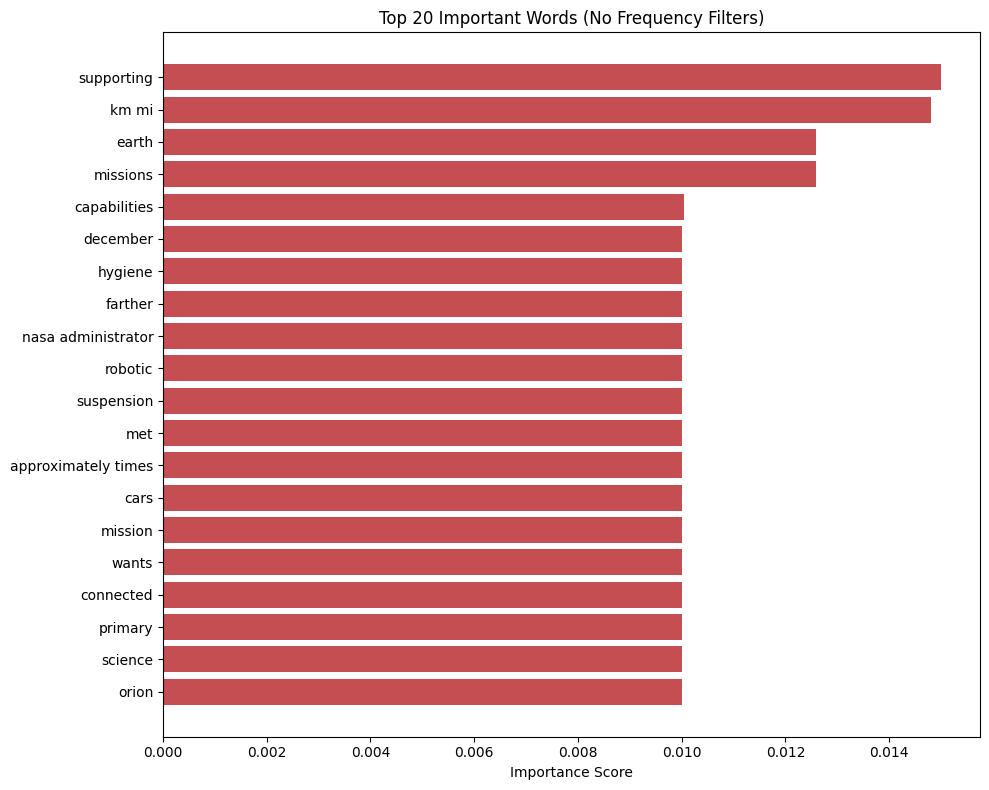

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize and train the machine learning algorithm
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_matrix, labels)

# 2. Extract the mathematical importance scores
importances = classifier.feature_importances_

# 3. Sort the scores to find the top 20 most valuable features
# Changed from [-10:] to [-20:]
indices = np.argsort(importances)[-20:][::-1]
top_features = [features[i] for i in indices]
top_scores = importances[indices]

# 4. Print the raw mathematical results
print("--- Top 20 Features (No Frequency Filters) ---")
for i in range(20):
    print(f"Feature: '{top_features[i].ljust(15)}' | Score: {top_scores[i]:.4f}")

# 5. Visualize the Feature Importances
# Increased height to figsize=(10, 8) to fit 20 bars cleanly
plt.figure(figsize=(10, 8))
plt.barh(top_features[::-1], top_scores[::-1], color='#C44E52')
plt.xlabel('Importance Score')
plt.title('Top 20 Important Words (No Frequency Filters)')
plt.tight_layout()
plt.show()

# Creates a Custom Tokenizer

first step creates a custom tokenizer that uses spaCy's dependency parser (Chapter 8) to automatically identify and extract complete Noun Phrases (Chapter 7) based on the sentence's grammatical tree.

In [20]:
import spacy

# 1. Load the NLP grammar engine (this includes the dependency parser from Ch 8)
nlp = spacy.load("en_core_web_sm")

# 2. Define a test function for Information Extraction (Ch 7)
def test_chunking(text):
    doc = nlp(text)
    print(f"Original Text: '{text}'\n")
    print("--- Extracted Grammatical Chunks ---")

    # doc.noun_chunks automatically groups nouns with their descriptive adjectives
    # based on the sentence's grammatical parse tree
    for chunk in doc.noun_chunks:
        # Clean the chunk: remove standard stop words (like "the", "a")
        # and keep only meaningful alphabetical words, converting them to their root form
        cleaned_chunk = [token.lemma_.lower() for token in chunk
                         if token.is_alpha and not token.is_stop]

        # Only print chunks that have at least one valid word
        if cleaned_chunk:
            phrase = " ".join(cleaned_chunk)
            print(f"Extracted Feature: '{phrase.ljust(20)}' | (Derived from raw text: '{chunk.text}')")

# 3. Test the grammar parser on a complex sample sentence
sample_sentence = "The massive, newly constructed space station orbits Earth."
test_chunking(sample_sentence)

Original Text: 'The massive, newly constructed space station orbits Earth.'

--- Extracted Grammatical Chunks ---
Extracted Feature: 'massive newly construct space station' | (Derived from raw text: 'The massive, newly constructed space station')
Extracted Feature: 'earth               ' | (Derived from raw text: 'Earth')


# Grammatical Chunk Extraction

Now that I have verified the grammar parser works on a single sentence, the next step is to apply this logic to entire 14-document dataset, train the Random Forest Classifier, and visualize the results.

By applying this chunking tokenizer to the TfidfVectorizer, I force the machine learning algorithm to learn from complete, semantic concepts instead of fragmented words.

Extracting grammatical noun chunks... (Parsing sentence structures)

--- Top 20 Features (Grammatical Chunk Extraction) ---
Feature: 'march                              ' | Score: 0.0242
Feature: 'october                            ' | Score: 0.0203
Feature: 'orbit                              ' | Score: 0.0174
Feature: 'm                                  ' | Score: 0.0172
Feature: 'mission                            ' | Score: 0.0158
Feature: 'evidence                           ' | Score: 0.0145
Feature: 'astronaut                          ' | Score: 0.0140
Feature: 'personnel                          ' | Score: 0.0131
Feature: 'form                               ' | Score: 0.0127
Feature: 'operation                          ' | Score: 0.0126
Feature: 'program                            ' | Score: 0.0125
Feature: 'vehicle                            ' | Score: 0.0121
Feature: 'study                              ' | Score: 0.0109
Feature: 'soviet probe                       ' | Score: 0

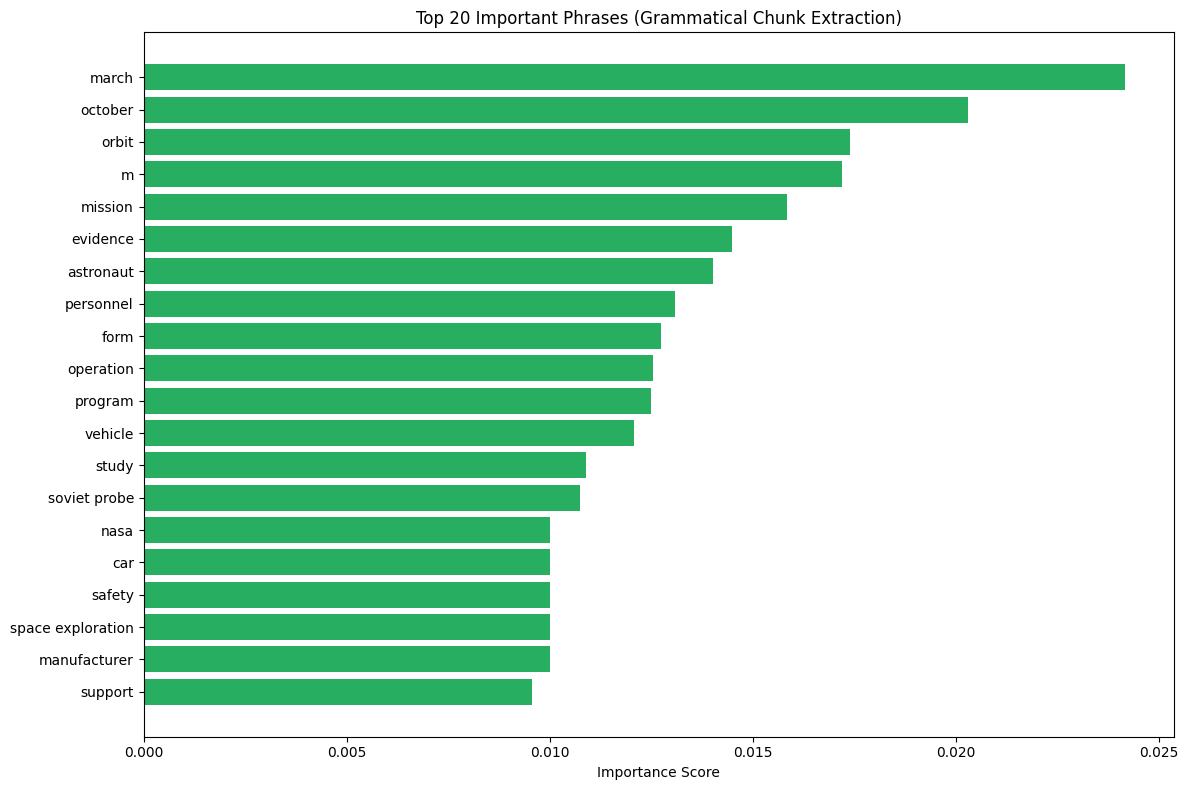

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Define the actual tokenizer for the pipeline using the tested logic
def chunking_tokenizer(text):
    doc = nlp(text)
    features = []
    for chunk in doc.noun_chunks:
        cleaned_chunk = [token.lemma_.lower() for token in chunk
                         if token.is_alpha and not token.is_stop]
        if cleaned_chunk:
            features.append(" ".join(cleaned_chunk))
    return features

# 2. Initialize the Vectorizer with the Chunking Tokenizer
chunk_vectorizer = TfidfVectorizer(
    tokenizer=chunking_tokenizer,
    stop_words='english',
    token_pattern=None,
    ngram_range=(1, 1)            # Set to 1 because the tokenizer dynamically builds the full phrase
)

# 3. Convert the documents into the mathematical matrix
print("Extracting grammatical noun chunks... (Parsing sentence structures)")
X_chunks = chunk_vectorizer.fit_transform(documents)
chunk_features = chunk_vectorizer.get_feature_names_out()

# 4. Train the Random Forest algorithm
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_chunks, labels)

# 5. Extract the top 20 importance scores
importances = classifier.feature_importances_
indices = np.argsort(importances)[-20:][::-1]
top_chunk_features = [chunk_features[i] for i in indices]
top_chunk_scores = importances[indices]

# 6. Print the newly generated chunk features
print("\n--- Top 20 Features (Grammatical Chunk Extraction) ---")
for i in range(20):
    print(f"Feature: '{top_chunk_features[i].ljust(35)}' | Score: {top_chunk_scores[i]:.4f}")

# 7. Visualize the Feature Importances
plt.figure(figsize=(12, 8))
plt.barh(top_chunk_features[::-1], top_chunk_scores[::-1], color='#27AE60')
plt.xlabel('Importance Score')
plt.title('Top 20 Important Phrases (Grammatical Chunk Extraction)')
plt.tight_layout()
plt.show()

 # Upgrade the Tokenizer

This code builds an advanced machine learning pipeline that uses grammatical structure and mathematical filters to classify text documents.

Load the NLP Engine: It initializes a pre-trained spaCy English language model to analyze the grammar and vocabulary of the text.

Define a Hybrid Tokenizer: A custom function translates raw text into meaningful phrases using two techniques:

Named Entity Recognition (NER): It uses an allowlist (valid_entity_types) to extract only specific, high-value entities (organizations, products, locations, facilities) while automatically dropping noisy dates and numbers.

Syntactic Noun Chunking: It parses the sentence tree to extract complete noun phrases, dropping punctuation and stop words, to capture full concepts (e.g., "internal combustion engine") instead of isolated words.

Initialize the Vectorizer: It sets up a TfidfVectorizer to convert text into numbers using the custom tokenizer. It applies mathematical boundaries: max_df=0.85 drops generic words appearing in over 85% of documents, and min_df=2 drops obscure trivia appearing in fewer than two documents.

Build the Matrix: It processes the training documents through the vectorizer, generating a clean mathematical matrix (X_final) of highly relevant features.

Train the Classifier: It feeds the clean matrix and the correct document categories (labels) into a Random Forest algorithm, teaching it which specific phrases predict a document's category.

Extract Feature Importance: It asks the trained algorithm to rank the top 20 most influential phrases it used to make its decisions.

Visualize the Results: It generates a horizontal bar chart using matplotlib to display the top 20 features and their importance scores

Extracting advanced features and applying mathematical filters...

--- Top 20 Features (Advanced NLP + Math Filters) ---
Feature: 'october                            ' | Score: 0.0321
Feature: 'orbit                              ' | Score: 0.0265
Feature: 'february                           ' | Score: 0.0265
Feature: 'automobile                         ' | Score: 0.0263
Feature: 'evidence                           ' | Score: 0.0200
Feature: 'preparation                        ' | Score: 0.0200
Feature: 'datum                              ' | Score: 0.0174
Feature: 'january                            ' | Score: 0.0172
Feature: 'space                              ' | Score: 0.0170
Feature: 'low earth orbit                    ' | Score: 0.0149
Feature: 'engine                             ' | Score: 0.0142
Feature: 'ocean                              ' | Score: 0.0128
Feature: 'c                                  ' | Score: 0.0125
Feature: 'problem                            ' | Score: 0.01

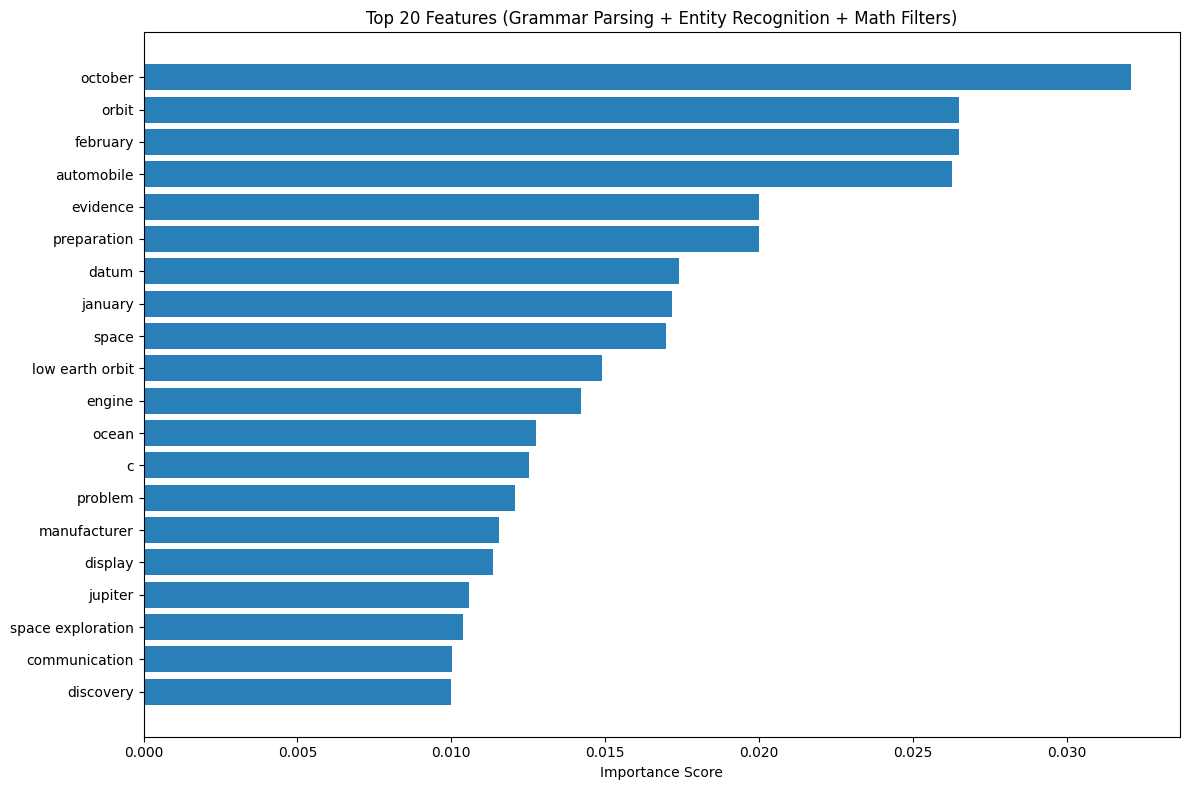

In [23]:
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Load the NLP grammar engine
nlp = spacy.load("en_core_web_sm")

# 2. Define the Advanced Hybrid Tokenizer
def advanced_nlp_tokenizer(text):
    doc = nlp(text)
    features = []

    # A. Information Extraction: Named Entities (Chapter 7)
    # Target specific entity types and strictly IGNORE dates, times, and numbers
    valid_entity_types = {'ORG', 'PRODUCT', 'GPE', 'LOC', 'FAC'}
    for ent in doc.ents:
        if ent.label_ in valid_entity_types:
            # Lemmatize the entity (e.g., "NASA" stays "nasa")
            features.append(ent.lemma_.lower())

    # B. Syntactic Parsing: Noun Chunks (Chapters 8 & 9)
    for chunk in doc.noun_chunks:
        # Check the grammatical feature of each token, dropping stop words and punctuation
        cleaned_chunk = [token.lemma_.lower() for token in chunk
                         if token.is_alpha and not token.is_stop]

        if cleaned_chunk:
            phrase = " ".join(cleaned_chunk)
            # Avoid duplicating a phrase if NER already extracted it
            if phrase not in features:
                features.append(phrase)

    return features

# 3. Initialize the Vectorizer with BOTH Linguistic and Mathematical Rules
final_vectorizer = TfidfVectorizer(
    tokenizer=advanced_nlp_tokenizer,
    stop_words='english',
    token_pattern=None,
    max_df=0.85,  # Mathematical Rule: Ban concepts appearing in >85% of documents
    min_df=2      # Mathematical Rule: Ban concepts appearing in fewer than 2 documents
)

# 4. Convert the documents into the final, cleaned mathematical matrix
print("Extracting advanced features and applying mathematical filters...")
X_final = final_vectorizer.fit_transform(documents)
final_features = final_vectorizer.get_feature_names_out()

# 5. Train the Random Forest algorithm
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_final, labels)

# 6. Extract the top 20 importance scores
importances = classifier.feature_importances_
indices = np.argsort(importances)[-20:][::-1]
top_final_features = [final_features[i] for i in indices]
top_final_scores = importances[indices]

# 7. Print the newly generated clean features
print("\n--- Top 20 Features (Advanced NLP + Math Filters) ---")
for i in range(20):
    print(f"Feature: '{top_final_features[i].ljust(35)}' | Score: {top_final_scores[i]:.4f}")

# 8. Visualize the Feature Importances
plt.figure(figsize=(12, 8))
plt.barh(top_final_features[::-1], top_final_scores[::-1], color='#2980B9')
plt.xlabel('Importance Score')
plt.title('Top 20 Features (Grammar Parsing + Entity Recognition + Math Filters)')
plt.tight_layout()
plt.show()

# Advanced Hybrid Tokenizer (Strict Filter Update)

This function acts as a highly strict linguistic filter, translating raw text into a final clean list of domain-specific concepts (features) for machine learning model. It uses a two-pronged approach to extract valuable phrases while ruthlessly blocking noise like dates, numbers, and stray letters.

Here is the step-by-step breakdown of how it works:

1. NLP Processing and Allowlist

doc = nlp(text): Feeds the raw text into the spaCy engine, which maps out the grammar, sentence structure, and named entities.

valid_entity_types: Defines a strict allowlist. It tells the algorithm to only care about Organizations, Products, Geopolitical Entities, Locations, and Facilities. Because it relies on an allowlist, it automatically ignores irrelevant entities like DATE, TIME, CARDINAL (numbers), and ORDINAL.

2. Part A: Named Entity Extraction

The function loops through every named entity (doc.ents) the NLP engine found.

If the entity matches one of the five approved categories, it converts the word to its lowercase, base dictionary form (ent.lemma_.lower()) and saves it to the feature list.

3. Part B: Noun Chunk Extraction (The Strict Filter)

The function loops through every grammatical noun phrase (doc.noun_chunks) found in the sentence's syntax tree.

It then evaluates every single word (token) inside that phrase against two severe filters:

Filter 1 (Format): The word must contain only alphabetical letters, it cannot be a common stop word (like "the" or "and"), and it must be longer than one letter. This instantly kills punctuation and single-character noise like "c" or "m".

Filter 2 (Entity Check): The word must either be an untagged normal word (like "engine" or "orbit") OR it must match the strict entity allowlist. This catches dates like "October" that the grammar engine mistakenly grouped into a noun phrase, blocking them from getting through.

Stitching: If the words survive the filters, they are stitched back together into a clean, lowercase phrase (e.g., "internal combustion engine").

Deduplication: It checks if the phrase was already extracted during Part A. If not, it adds the phrase to the final feature list.

4. The Output

return features: The function returns a completely clean list of high-value vocabulary words and phrases, free of dates, numbers, and single-letter artifacts, ready to be turned into a mathematical matrix.

In [25]:
# 1. Define the Advanced Hybrid Tokenizer (Strict Filter Update)
def advanced_nlp_tokenizer(text):
    doc = nlp(text)
    features = []

    valid_entity_types = {'ORG', 'PRODUCT', 'GPE', 'LOC', 'FAC'}

    # A. Information Extraction: Named Entities
    for ent in doc.ents:
        if ent.label_ in valid_entity_types:
            features.append(ent.lemma_.lower())

    # B. Syntactic Parsing: Noun Chunks
    for chunk in doc.noun_chunks:
        cleaned_chunk = []
        for token in chunk:
            # 1. Must be alphabetical, not a stop word, and longer than 1 letter (drops 'c', 'm')
            if token.is_alpha and not token.is_stop and len(token.lemma_) > 1:
                # 2. Token must either be untagged OR match our valid entity allowlist
                # This explicitly blocks tokens tagged as DATE, TIME, CARDINAL, etc.
                if token.ent_type_ == "" or token.ent_type_ in valid_entity_types:
                    cleaned_chunk.append(token.lemma_.lower())

        if cleaned_chunk:
            phrase = " ".join(cleaned_chunk)
            if phrase not in features:
                features.append(phrase)

    return features

# Setting the Rules (TfidfVectorizer)
We are defining the exact blueprint for how text should be converted into numbers. By passing tokenizer=advanced_nlp_tokenizer, we are telling the vectorizer to use custom grammatical chunking and entity allowlist. We are also combining this with mathematical frequency filters: max_df=0.85 drops overly generic words that appear in more than 85% of the documents, and min_df=2 drops highly obscure words (or typos) that appear in fewer than two documents.

# Building the Matrix (fit_transform)
The .fit_transform(documents) command executes the blueprint. It reads through all 14 of Wikipedia documents, applies the strict NLP filtering rules, calculates the frequency filters, and outputs X_final—a clean, pristine mathematical matrix where every column is a high-value domain concept (like "hubble space telescope" or "internal combustion engine").

# Training the Algorithm (RandomForestClassifier)
We initialize the Random Forest machine learning model and use .fit(X_final, labels) to train it. The algorithm looks at the pristine mathematical matrix (X_final) and the correct answers (labels—0 for Space, 1 for Autos). It learns the patterns, figuring out exactly which grammatical phrases strongly indicate a Space article and which indicate an Automobile article.

Extracting pristine features and training the model...

--- Top 20 Features (Advanced NLP + Math Filters) ---
Feature: 'nasa                               ' | Score: 0.0353
Feature: 'space                              ' | Score: 0.0327
Feature: 'altitude                           ' | Score: 0.0247
Feature: 'mission                            ' | Score: 0.0239
Feature: 'ford                               ' | Score: 0.0210
Feature: 'orbit                              ' | Score: 0.0210
Feature: 'ocean                              ' | Score: 0.0200
Feature: 'evidence                           ' | Score: 0.0194
Feature: 'low earth orbit                    ' | Score: 0.0175
Feature: 'earth                              ' | Score: 0.0163
Feature: 'center                             ' | Score: 0.0153
Feature: 'astronaut                          ' | Score: 0.0149
Feature: 'number                             ' | Score: 0.0131
Feature: 'effect                             ' | Score: 0.0121
Feature:

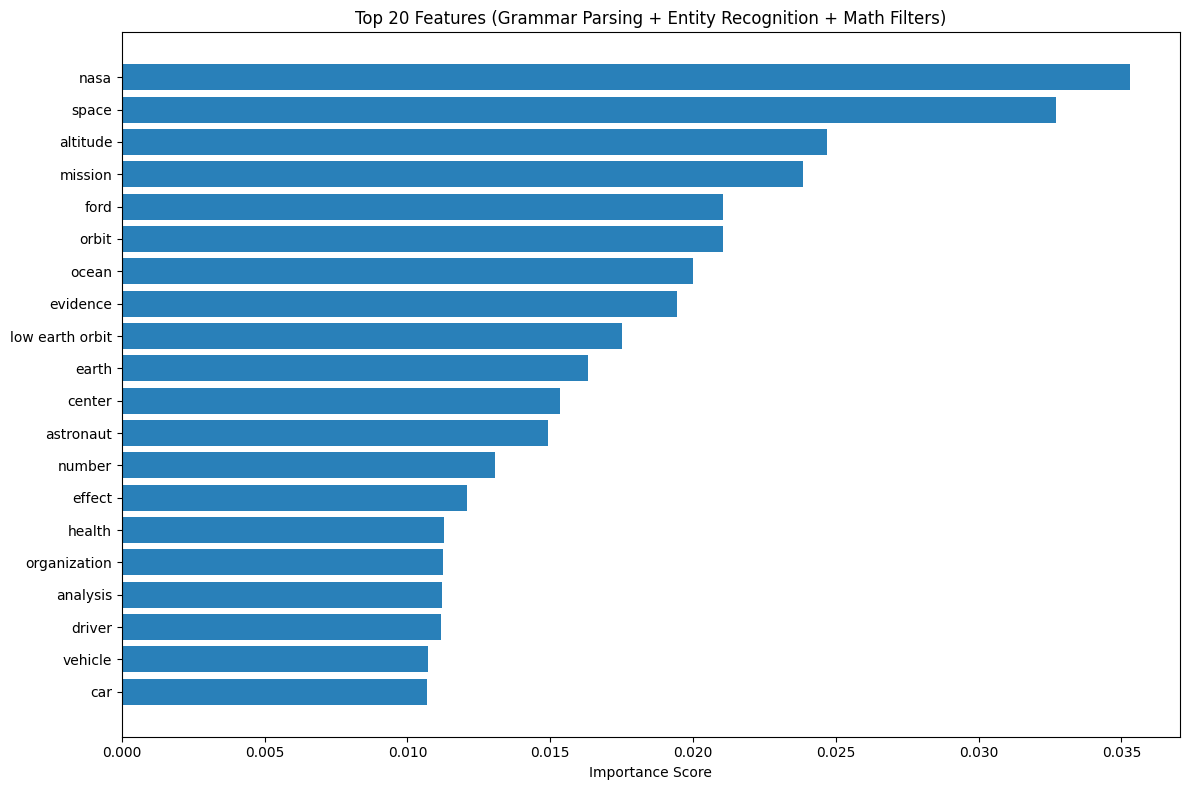

In [26]:
# 1. Initialize the Vectorizer with BOTH Linguistic and Mathematical Rules
final_vectorizer = TfidfVectorizer(
    tokenizer=advanced_nlp_tokenizer, # Pointed to strictly filtered function
    stop_words='english',
    token_pattern=None,
    max_df=0.85,  # Ban concepts in >85% of documents
    min_df=2      # Ban concepts in fewer than 2 documents
)

# 2. Convert the documents into the final, cleaned mathematical matrix
print("Extracting pristine features and training the model...")
X_final = final_vectorizer.fit_transform(documents)
final_features = final_vectorizer.get_feature_names_out()

# 3. Train the Random Forest algorithm
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_final, labels)

# Extract and display the top 20 importance scores
importances = classifier.feature_importances_
indices = np.argsort(importances)[-20:][::-1]
top_final_features = [final_features[i] for i in indices]
top_final_scores = importances[indices]

print("\n--- Top 20 Features (Advanced NLP + Math Filters) ---")
for i in range(20):
    print(f"Feature: '{top_final_features[i].ljust(35)}' | Score: {top_final_scores[i]:.4f}")

# 7. Visualize the Feature Importances
plt.figure(figsize=(12, 8))
plt.barh(top_final_features[::-1], top_final_scores[::-1], color='#2980B9')
plt.xlabel('Importance Score')
plt.title('Top 20 Features (Grammar Parsing + Entity Recognition + Math Filters)')
plt.tight_layout()
plt.show()



In [27]:
# ==========================================
# STEP 4: PREDICTING NEW DOCUMENTS
# ==========================================
# 8. Define completely new, unseen URLs
test_urls = [
    "https://en.wikipedia.org/wiki/James_Webb_Space_Telescope",  # Unseen Space page
    "https://en.wikipedia.org/wiki/Truck",          # Unseen Auto page
    "https://en.wikipedia.org/wiki/Apollo_program",  # New Space page
    "https://en.wikipedia.org/wiki/Motorcycle"      # New Auto page
]

# 9. Scrape the text from these new URLs
new_docs = []
print("\nDownloading unseen test documents...")
for link in test_urls:
    new_docs.append(fetch_clean_text(link))

# 10. Translate the new text into math using the LOCKED dictionary
# CRITICAL: Use .transform(), NOT .fit_transform()
X_new = final_vectorizer.transform(new_docs)

# 11. Ask the trained algorithm to predict the categories
predictions = classifier.predict(X_new)

# 12. Display the final results
print("\n--- Final Predictions on Unseen Documents ---")
for i in range(len(test_urls)):
    url_name = test_urls[i].split('/')[-1]
    predicted_label = predictions[i]

    category = "Space" if predicted_label == 0 else "Automobiles"
    print(f"Document: {url_name.ljust(30)} | Predicted Category: {category} (Label {predicted_label})")



--- Final Predictions on Unseen Documents ---
Document: James_Webb_Space_Telescope     | Predicted Category: Space (Label 0)
Document: Truck                          | Predicted Category: Automobiles (Label 1)
Document: Apollo_program                 | Predicted Category: Space (Label 0)
Document: Motorcycle                     | Predicted Category: Automobiles (Label 1)
